In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("india_housing_prices.csv")

df.head()

,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,...,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,...,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,...,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,...,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,...,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,...,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


In [3]:
# Check the number of rows and columns
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset Information:")
df.info()

# Check missing values in each column
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (250000, 23)

Column Names:
['ID', 'State', 'City', 'Locality', 'Property_Type', 'BHK', 'Size_in_SqFt', 'Price_in_Lakhs', 'Price_per_SqFt', 'Year_Built', 'Furnished_Status', 'Floor_No', 'Total_Floors', 'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals', 'Public_Transport_Accessibility', 'Parking_Space', 'Security', 'Amenities', 'Facing', 'Owner_Type', 'Availability_Status']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 23 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   ID                              250000 non-null  int64  
 1   State                           250000 non-null  str    
 2   City                            250000 non-null  str    
 3   Locality                        250000 non-null  str    
 4   Property_Type                   250000 non-null  str    
 5   BHK                             250000 non

In [4]:
from sklearn.preprocessing import MinMaxScaler

# Select numerical columns for scaling
numerical_cols = [
    "BHK",
    "Size_in_SqFt",
    "Price_in_Lakhs",
    "Price_per_SqFt",
    "Year_Built",
    "Floor_No",
    "Total_Floors",
    "Age_of_Property",
    "Nearby_Schools",
    "Nearby_Hospitals"
]

# Create a copy of the original dataset
df_scaled = df.copy()

# Create MinMaxScaler
scaler = MinMaxScaler()

# Scale numerical columns
df_scaled[numerical_cols] = scaler.fit_transform(
    df[numerical_cols]
)

# Display the scaled values
df_scaled[numerical_cols].head()

,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals
0,0.00,0.942222,0.979102,0.101010,0.000000,0.733333,0.000000,1.000000,1.000000,0.222222
1,0.50,0.414222,0.378612,0.080808,0.545455,0.700000,0.655172,0.454545,0.777778,0.000000
2,0.25,0.698222,0.354673,0.050505,0.212121,0.633333,0.896552,0.787879,0.888889,0.777778
3,0.25,0.498000,0.592429,0.111111,0.030303,0.700000,0.862069,0.969697,0.444444,0.666667
4,0.75,0.960667,0.352857,0.040404,0.363636,0.100000,0.034483,0.636364,0.333333,0.888889


In [5]:
# Identify categorical columns
categorical_cols = df.select_dtypes(
    include=["object", "str"]
).columns.tolist()

print("Categorical Columns:")
print(categorical_cols)

Categorical Columns:
['State', 'City', 'Locality', 'Property_Type', 'Furnished_Status', 'Public_Transport_Accessibility', 'Parking_Space', 'Security', 'Amenities', 'Facing', 'Owner_Type', 'Availability_Status']


In [9]:
print("Categorical Encoding Started")

print("Original shape:", df.shape)
print("Categorical columns:", len(categorical_cols))

Categorical Encoding Started
Original shape: (250000, 23)
Categorical columns: 12


In [11]:
import pandas as pd

# Encode categorical features
df_encoded = pd.get_dummies(
    df,
    columns=["State", "City", "Locality", "Property_Type"],
    dtype=int
)

# Display the first 5 rows
df_encoded.head()

,ID,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,...,Locality_Locality_93,Locality_Locality_94,Locality_Locality_95,Locality_Locality_96,Locality_Locality_97,Locality_Locality_98,Locality_Locality_99,Property_Type_Apartment,Property_Type_Independent House,Property_Type_Villa
0,1,1,4740,489.76,0.10,1990,Furnished,22,1,35,...,0,0,0,0,0,0,0,1,0,0
1,2,3,2364,195.52,0.08,2008,Unfurnished,21,20,17,...,0,0,0,0,0,0,0,0,1,0
2,3,2,3642,183.79,0.05,1997,Semi-furnished,19,27,28,...,0,0,0,0,0,0,0,1,0,0
3,4,2,2741,300.29,0.11,1991,Furnished,21,26,34,...,0,0,0,0,0,0,0,0,1,0
4,5,4,4823,182.90,0.04,2002,Semi-furnished,3,2,23,...,0,0,0,0,0,0,0,0,0,1


In [15]:
# Create new features

df["Nearby_Facilities_Total"] = (
    df["Nearby_Schools"] + df["Nearby_Hospitals"]
)

df["School_Density_Score"] = df["Nearby_Schools"]

# Display the new features
df[[
    "Nearby_Schools",
    "Nearby_Hospitals",
    "Nearby_Facilities_Total",
    "School_Density_Score"
]].head()

,Nearby_Schools,Nearby_Hospitals,Nearby_Facilities_Total,School_Density_Score
0,10,3,13,10
1,8,1,9,8
2,9,8,17,9
3,5,7,12,5
4,4,9,13,4


In [16]:
print(df[[
    "Nearby_Schools",
    "Nearby_Hospitals",
    "Nearby_Facilities_Total",
    "School_Density_Score"
]].head().to_string(index=False))

 Nearby_Schools  Nearby_Hospitals  Nearby_Facilities_Total  School_Density_Score
             10                 3                       13                    10
              8                 1                        9                     8
              9                 8                       17                     9
              5                 7                       12                     5
              4                 9                       13                     4


In [17]:
df["Price_per_SqFt"].median()

np.float64(0.09)

In [18]:
df["Price_per_SqFt"].describe()

count    250000.000000
mean          0.130597
std           0.130747
min           0.000000
25%           0.050000
50%           0.090000
75%           0.160000
max           0.990000
Name: Price_per_SqFt, dtype: float64

In [19]:
print(df[["Price_in_Lakhs", "Price_per_SqFt"]].head())

   Price_in_Lakhs  Price_per_SqFt
0          489.76            0.10
1          195.52            0.08
2          183.79            0.05
3          300.29            0.11
4          182.90            0.04


In [20]:
# Create a proxy label for Good Investment
good_price = df["Price_per_SqFt"] <= df["Price_per_SqFt"].median()
good_schools = df["Nearby_Schools"] >= df["Nearby_Schools"].median()
good_hospitals = df["Nearby_Hospitals"] >= df["Nearby_Hospitals"].median()

df["Good_Investment"] = (
    good_price & good_schools & good_hospitals
).astype(int)

# Check label counts
print(df["Good_Investment"].value_counts())

Good_Investment
0    203607
1     46393
Name: count, dtype: int64


In [22]:
df[[
    "Price_per_SqFt",
    "Nearby_Facilities_Total",
    "School_Density_Score",
    "Good_Investment"
]].head().to_string(index=False)

' Price_per_SqFt  Nearby_Facilities_Total  School_Density_Score  Good_Investment\n           0.10                       13                    10                0\n           0.08                        9                     8                0\n           0.05                       17                     9                1\n           0.11                       12                     5                0\n           0.04                       13                     4                0'

In [23]:
# Separate features (X) and target (y)

X = df.drop(columns=[
    "ID",
    "Good_Investment",
    "Price_per_SqFt",
    "Nearby_Schools",
    "Nearby_Hospitals",
    "Nearby_Facilities_Total",
    "School_Density_Score"
])

y = df["Good_Investment"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (250000, 19)
y shape: (250000,)


In [24]:
df["Public_Transport_Accessibility"].value_counts()

Public_Transport_Accessibility
High      83705
Low       83287
Medium    83008
Name: count, dtype: int64

In [25]:
# Define investment conditions
good_price = df["Price_per_SqFt"] <= df["Price_per_SqFt"].median()

good_schools = df["Nearby_Schools"] >= df["Nearby_Schools"].median()

good_hospitals = df["Nearby_Hospitals"] >= df["Nearby_Hospitals"].median()

good_transport = df["Public_Transport_Accessibility"] == "High"

# Create updated Good_Investment label
df["Good_Investment"] = (
    good_price &
    good_schools &
    good_hospitals &
    good_transport
).astype(int)

# Check the result
print(df["Good_Investment"].value_counts())

Good_Investment
0    234417
1     15583
Name: count, dtype: int64


In [26]:
# Separate features (X) and target (y)

X = df.drop(columns=[
    "ID",
    "Good_Investment",
    "Price_per_SqFt",
    "Nearby_Schools",
    "Nearby_Hospitals",
    "Nearby_Facilities_Total",
    "School_Density_Score"
])

y = df["Good_Investment"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (250000, 19)
y shape: (250000,)


In [27]:
categorical_cols = X.select_dtypes(
    include=["object", "str"]
).columns.tolist()

print(categorical_cols)

['State', 'City', 'Locality', 'Property_Type', 'Furnished_Status', 'Public_Transport_Accessibility', 'Parking_Space', 'Security', 'Amenities', 'Facing', 'Owner_Type', 'Availability_Status']


In [28]:
for col in categorical_cols:
    print(col, ":", X[col].nunique())

State : 20
City : 42
Locality : 500
Property_Type : 3
Furnished_Status : 3
Public_Transport_Accessibility : 3
Parking_Space : 2
Security : 2
Amenities : 325
Facing : 4
Owner_Type : 3
Availability_Status : 2


In [29]:
# Select categorical columns except Locality and Amenities

small_cat_cols = [
    col for col in categorical_cols
    if col not in ["Locality", "Amenities"]
]

# One-Hot Encoding
X_encoded = pd.get_dummies(
    X,
    columns=small_cat_cols,
    dtype=int
)

print("Original X shape:", X.shape)
print("Encoded X shape:", X_encoded.shape)

Original X shape: (250000, 19)
Encoded X shape: (250000, 93)


In [30]:
# Frequency Encoding for Locality

locality_freq = X["Locality"].value_counts(normalize=True)

X_encoded["Locality_Frequency"] = (
    X["Locality"].map(locality_freq)
)

X_encoded.head()

,Locality,BHK,Size_in_SqFt,Price_in_Lakhs,Year_Built,Floor_No,Total_Floors,Age_of_Property,Amenities,State_Andhra Pradesh,...,Facing_East,Facing_North,Facing_South,Facing_West,Owner_Type_Broker,Owner_Type_Builder,Owner_Type_Owner,Availability_Status_Ready_to_Move,Availability_Status_Under_Construction,Locality_Frequency
0,Locality_84,1,4740,489.76,1990,22,1,35,"Playground, Gym, Garden, Pool, Clubhouse",0,...,0,0,0,1,0,0,1,1,0,0.001936
1,Locality_490,3,2364,195.52,2008,21,20,17,"Playground, Clubhouse, Pool, Gym, Garden",0,...,0,1,0,0,0,1,0,0,1,0.002060
2,Locality_167,2,3642,183.79,1997,19,27,28,"Clubhouse, Pool, Playground, Gym",0,...,0,0,1,0,1,0,0,1,0,0.002040
3,Locality_393,2,2741,300.29,1991,21,26,34,"Playground, Clubhouse, Gym, Pool, Garden",0,...,0,1,0,0,0,1,0,1,0,0.002116
4,Locality_466,4,4823,182.90,2002,3,2,23,"Playground, Garden, Gym, Pool, Clubhouse",0,...,1,0,0,0,0,1,0,1,0,0.002048


In [31]:
# Remove original Locality column
X_encoded = X_encoded.drop(columns=["Locality"])

# Check the result
X_encoded[["Locality_Frequency"]].head()

,Locality_Frequency
0,0.001936
1,0.002060
2,0.002040
3,0.002116
4,0.002048


In [32]:
X["Amenities"].head(10)

0    Playground, Gym, Garden, Pool, Clubhouse
1    Playground, Clubhouse, Pool, Gym, Garden
2            Clubhouse, Pool, Playground, Gym
3    Playground, Clubhouse, Gym, Pool, Garden
4    Playground, Garden, Gym, Pool, Clubhouse
5                       Playground, Clubhouse
6               Clubhouse, Garden, Playground
7            Gym, Pool, Clubhouse, Playground
8               Garden, Clubhouse, Playground
9          Clubhouse, Playground, Garden, Gym
Name: Amenities, dtype: str

In [33]:
# Split amenities into separate binary columns
amenities_encoded = X["Amenities"].str.get_dummies(sep=", ")

# Add encoded columns to X_encoded
X_encoded = pd.concat(
    [X_encoded, amenities_encoded],
    axis=1
)

# Display the result
amenities_encoded.head()

,Clubhouse,Garden,Gym,Playground,Pool
0,1,1,1,1,1
1,1,1,1,1,1
2,1,0,1,1,1
3,1,1,1,1,1
4,1,1,1,1,1


In [36]:
print(X_encoded.columns.tolist())

['BHK', 'Size_in_SqFt', 'Price_in_Lakhs', 'Year_Built', 'Floor_No', 'Total_Floors', 'Age_of_Property', 'State_Andhra Pradesh', 'State_Assam', 'State_Bihar', 'State_Chhattisgarh', 'State_Delhi', 'State_Gujarat', 'State_Haryana', 'State_Jharkhand', 'State_Karnataka', 'State_Kerala', 'State_Madhya Pradesh', 'State_Maharashtra', 'State_Odisha', 'State_Punjab', 'State_Rajasthan', 'State_Tamil Nadu', 'State_Telangana', 'State_Uttar Pradesh', 'State_Uttarakhand', 'State_West Bengal', 'City_Ahmedabad', 'City_Amritsar', 'City_Bangalore', 'City_Bhopal', 'City_Bhubaneswar', 'City_Bilaspur', 'City_Chennai', 'City_Coimbatore', 'City_Cuttack', 'City_Dehradun', 'City_Durgapur', 'City_Dwarka', 'City_Faridabad', 'City_Gaya', 'City_Gurgaon', 'City_Guwahati', 'City_Haridwar', 'City_Hyderabad', 'City_Indore', 'City_Jaipur', 'City_Jamshedpur', 'City_Jodhpur', 'City_Kochi', 'City_Kolkata', 'City_Lucknow', 'City_Ludhiana', 'City_Mangalore', 'City_Mumbai', 'City_Mysore', 'City_Nagpur', 'City_New Delhi', 'City

In [37]:
X_encoded.select_dtypes(include=["object", "str"]).columns.tolist()

[]

In [40]:
[col for col in X_encoded.columns if "Public_Transport" in col]

[]

In [41]:
X_encoded.shape

(250000, 94)

In [42]:
city_price = df.groupby("City")["Price_in_Lakhs"].mean()

city_price = city_price.sort_values(ascending=False)

city_price.head(10)

City
Bangalore     258.456639
Surat         258.080467
Kochi         257.415221
Gaya          257.053391
Mangalore     256.920925
Dehradun      256.890115
Mysore        256.848172
Chennai       256.830172
Hyderabad     256.594051
Coimbatore    256.504745
Name: Price_in_Lakhs, dtype: float64

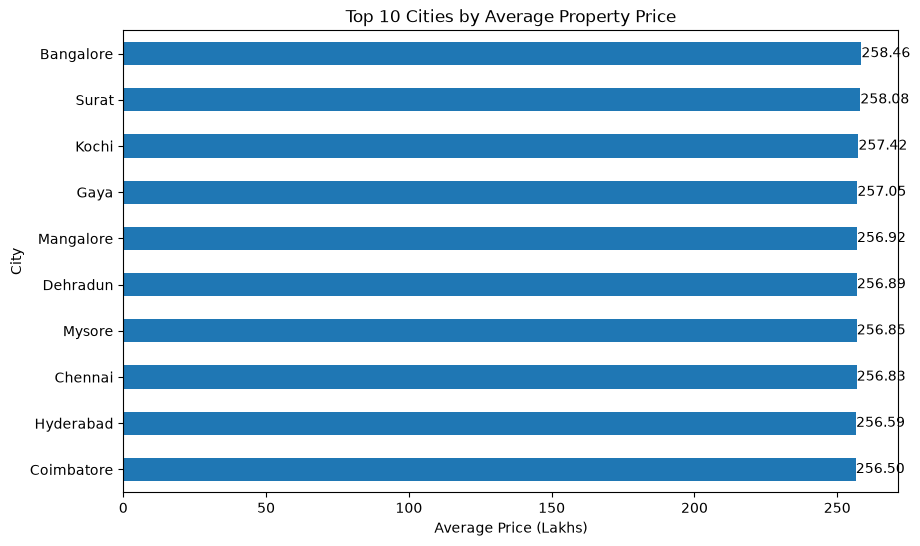

In [44]:
ax = city_price.head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

ax.bar_label(ax.containers[0], fmt="%.2f")

plt.title("Top 10 Cities by Average Property Price")
plt.xlabel("Average Price (Lakhs)")
plt.ylabel("City")
plt.show()

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

In [9]:
print(df.columns.tolist())

['ID', 'State', 'City', 'Locality', 'Property_Type', 'BHK', 'Size_in_SqFt', 'Price_in_Lakhs', 'Price_per_SqFt', 'Year_Built', 'Furnished_Status', 'Floor_No', 'Total_Floors', 'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals', 'Public_Transport_Accessibility', 'Parking_Space', 'Security', 'Amenities', 'Facing', 'Owner_Type', 'Availability_Status']


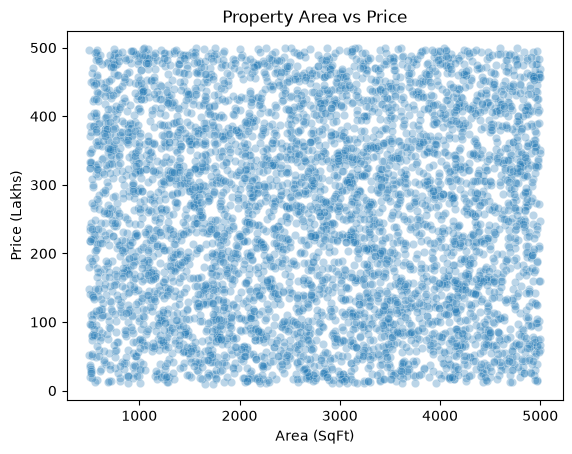

In [10]:
sns.scatterplot(
    data=df.sample(min(5000, len(df)), random_state=1),
    x="Size_in_SqFt",
    y="Price_in_Lakhs",
    alpha=0.3
)

plt.title("Property Area vs Price")
plt.xlabel("Area (SqFt)")
plt.ylabel("Price (Lakhs)")
plt.show()

In [11]:
df["Size_in_SqFt"].corr(df["Price_in_Lakhs"])


np.float64(-0.00252854679253891)

In [12]:
df["Security"].value_counts()

Security
Yes    125233
No     124767
Name: count, dtype: int64

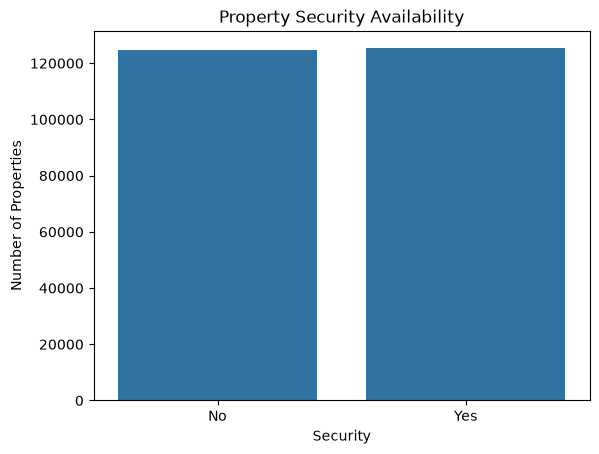

In [13]:
sns.countplot(data=df, x="Security")

plt.title("Property Security Availability")
plt.xlabel("Security")
plt.ylabel("Number of Properties")
plt.show()

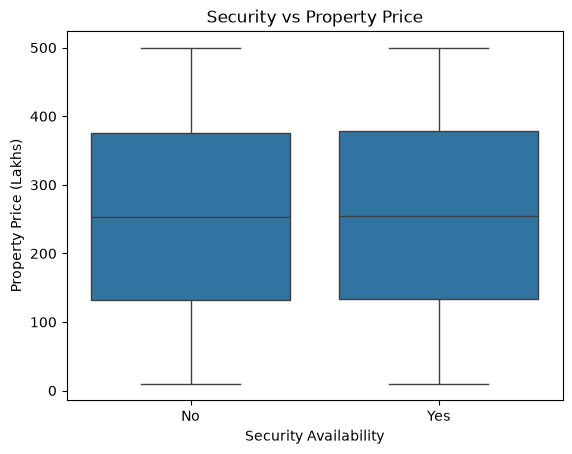

In [14]:
sns.boxplot(
    data=df,
    x="Security",
    y="Price_in_Lakhs"
)

plt.title("Security vs Property Price")
plt.xlabel("Security Availability")
plt.ylabel("Property Price (Lakhs)")
plt.show()

In [15]:
df.groupby("Security")["Price_in_Lakhs"].mean()

Security
No     254.047530
Yes    255.124171
Name: Price_in_Lakhs, dtype: float64

In [19]:
# Convert accessibility into numeric scores
df["Transport_Score"] = df["Public_Transport_Accessibility"].map({
    "High": 3,
    "Medium": 2,
    "Low": 1
})

# Create infrastructure score
df["Infrastructure_Score"] = (
    df["Transport_Score"] +
    df["Nearby_Schools"] +
    df["Nearby_Hospitals"]
)

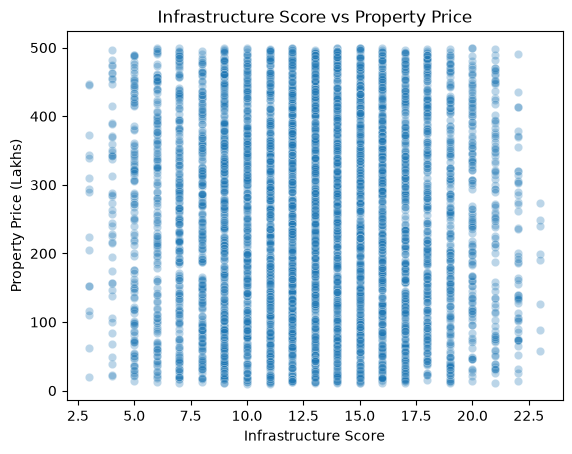

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(
    data=df.sample(5000, random_state=1),
    x="Infrastructure_Score",
    y="Price_in_Lakhs",
    alpha=0.3
)

plt.title("Infrastructure Score vs Property Price")
plt.xlabel("Infrastructure Score")
plt.ylabel("Property Price (Lakhs)")
plt.show()

In [21]:
df["Infrastructure_Score"].corr(df["Price_in_Lakhs"])

np.float64(-0.0017790190506095569)

What is the distribution of property prices?

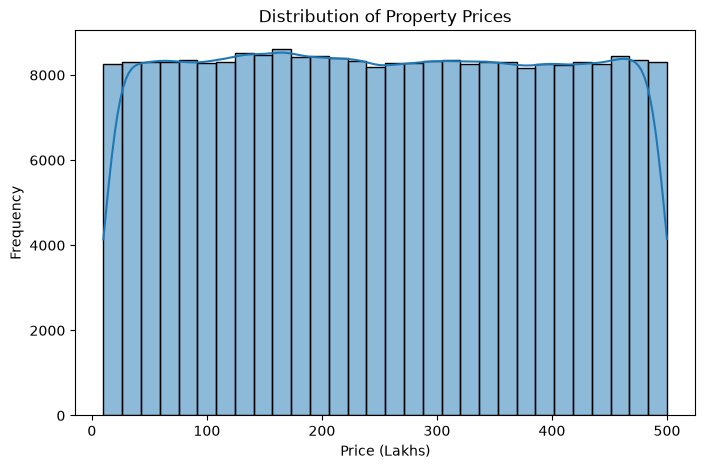

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.histplot(data=df, x="Price_in_Lakhs", bins=30, kde=True)

plt.title("Distribution of Property Prices")
plt.xlabel("Price (Lakhs)")
plt.ylabel("Frequency")
plt.show()

What is the distribution of property sizes?

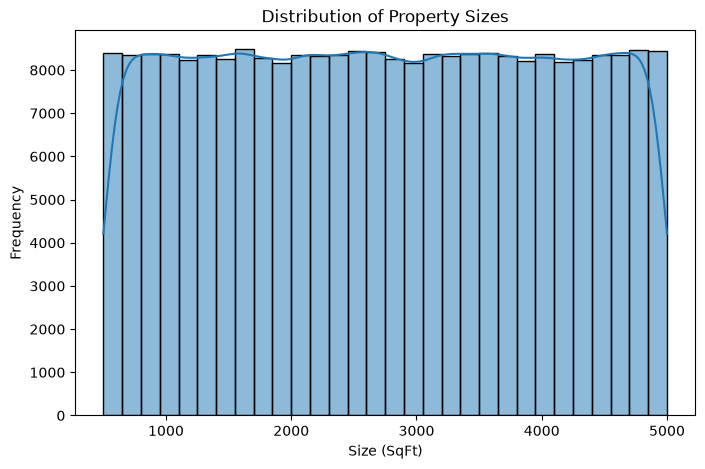

In [7]:
plt.figure(figsize=(8,5))
sns.histplot(data=df, x="Size_in_SqFt", bins=30, kde=True)

plt.title("Distribution of Property Sizes")
plt.xlabel("Size (SqFt)")
plt.ylabel("Frequency")
plt.show()

How does price per sq ft vary by property type?

In [24]:
df.groupby("Property_Type")["Price_per_SqFt"].mean()

Property_Type
Apartment            0.130493
Independent House    0.131023
Villa                0.130276
Name: Price_per_SqFt, dtype: float64

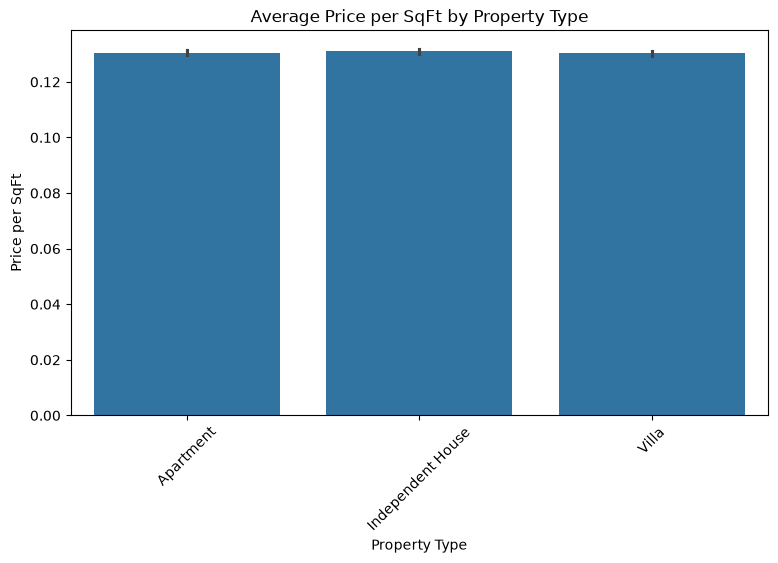

In [25]:
plt.figure(figsize=(9,5))
sns.barplot(data=df, x="Property_Type", y="Price_per_SqFt")

plt.title("Average Price per SqFt by Property Type")
plt.xlabel("Property Type")
plt.ylabel("Price per SqFt")
plt.xticks(rotation=45)
plt.show()

Is there a relationship between property size and price?

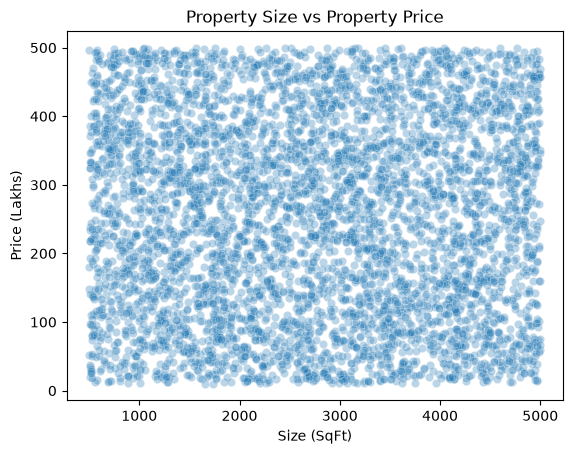

In [26]:
sample_df = df.sample(5000, random_state=1)

sns.scatterplot(
    data=sample_df,
    x="Size_in_SqFt",
    y="Price_in_Lakhs",
    alpha=0.3
)

plt.title("Property Size vs Property Price")
plt.xlabel("Size (SqFt)")
plt.ylabel("Price (Lakhs)")
plt.show()

In [27]:
df["Size_in_SqFt"].corr(df["Price_in_Lakhs"])

np.float64(-0.00252854679253891)

Are there any outliers in price per sq ft or property size?

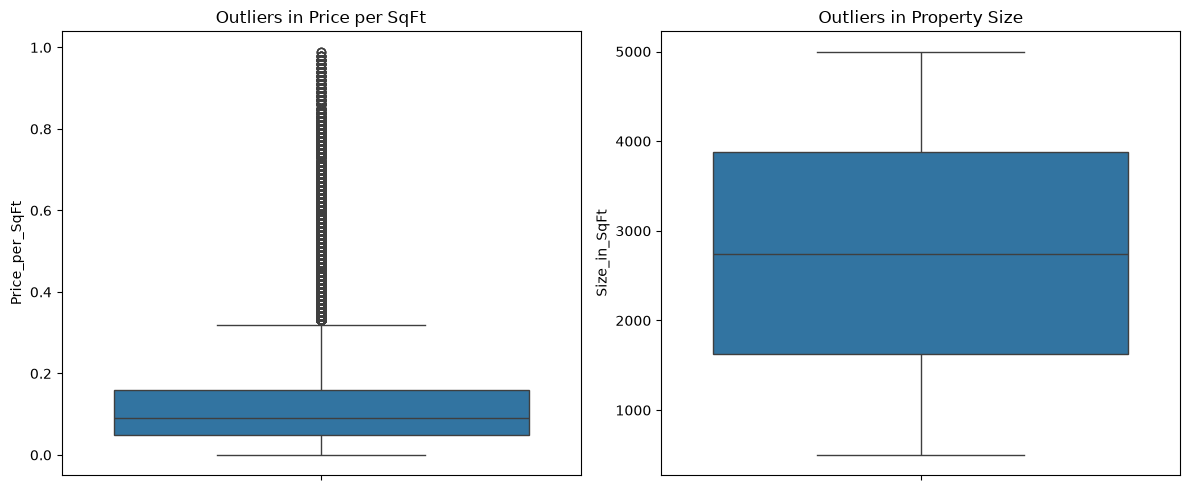

In [29]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.boxplot(y=df["Price_per_SqFt"])
plt.title("Outliers in Price per SqFt")

plt.subplot(1,2,2)
sns.boxplot(y=df["Size_in_SqFt"])
plt.title("Outliers in Property Size")

plt.tight_layout()
plt.show()

What is the average price per sq ft by state?

In [30]:
df.groupby("State")["Price_per_SqFt"].mean().sort_values(ascending=False)

State
Karnataka         0.132538
Andhra Pradesh    0.132037
Uttar Pradesh     0.131417
Tamil Nadu        0.131367
Gujarat           0.130995
Telangana         0.130957
Assam             0.130819
Madhya Pradesh    0.130717
Maharashtra       0.130703
Haryana           0.130692
West Bengal       0.130645
Bihar             0.130513
Odisha            0.130322
Uttarakhand       0.130245
Chhattisgarh      0.130243
Kerala            0.129849
Jharkhand         0.129754
Delhi             0.129477
Rajasthan         0.129336
Punjab            0.129311
Name: Price_per_SqFt, dtype: float64

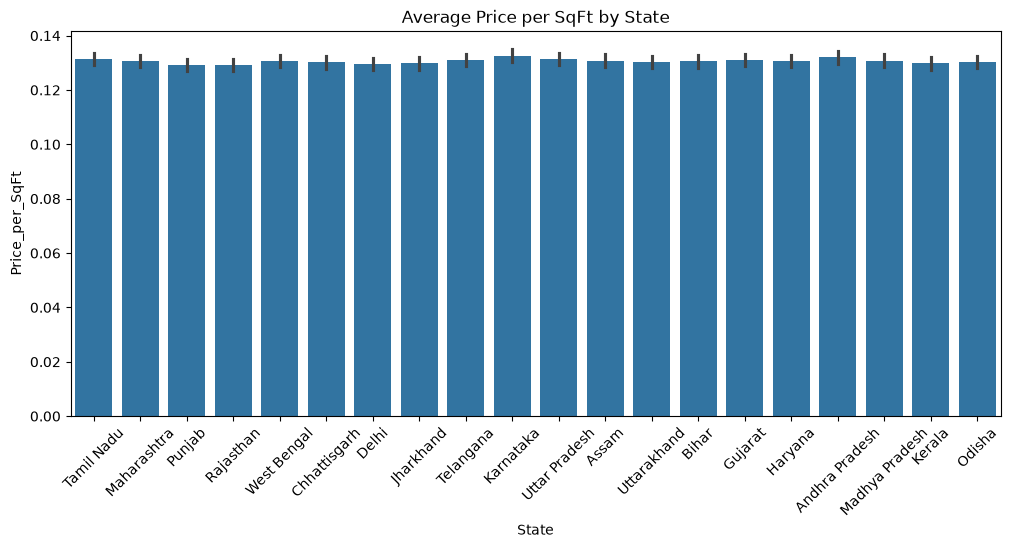

In [31]:
plt.figure(figsize=(12,5))

sns.barplot(
    data=df,
    x="State",
    y="Price_per_SqFt",
    estimator="mean"
)

plt.title("Average Price per SqFt by State")
plt.xticks(rotation=45)
plt.show()

What is the average property price by city?

In [32]:
df.groupby("City")["Price_in_Lakhs"].mean().sort_values(ascending=False)

City
Bangalore         258.456639
Surat             258.080467
Kochi             257.415221
Gaya              257.053391
Mangalore         256.920925
Dehradun          256.890115
Mysore            256.848172
Chennai           256.830172
Hyderabad         256.594051
Coimbatore        256.504745
Bhopal            256.498896
Pune              256.495661
Noida             256.287206
Lucknow           256.212431
Vishakhapatnam    255.772442
Nagpur            255.532012
Indore            255.413825
Jaipur            255.246241
Bhubaneswar       254.902173
Faridabad         254.862393
Vijayawada        254.643766
Ranchi            254.624529
Warangal          254.475113
Durgapur          254.100152
Gurgaon           254.027549
Jodhpur           253.947906
Kolkata           253.914897
Ahmedabad         253.586827
Raipur            253.482416
Dwarka            253.454299
Ludhiana          253.159636
Guwahati          252.992710
Patna             252.794673
Jamshedpur        252.626185
Silchar  

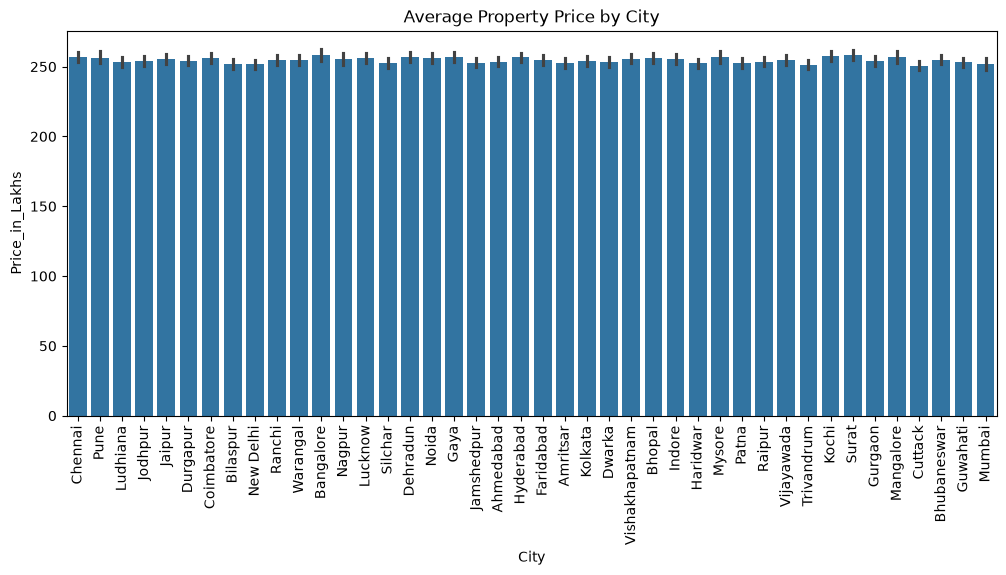

In [33]:
plt.figure(figsize=(12,5))

sns.barplot(
    data=df,
    x="City",
    y="Price_in_Lakhs",
    estimator="mean"
)

plt.title("Average Property Price by City")
plt.xticks(rotation=90)
plt.show()

What is the median age of properties by locality?

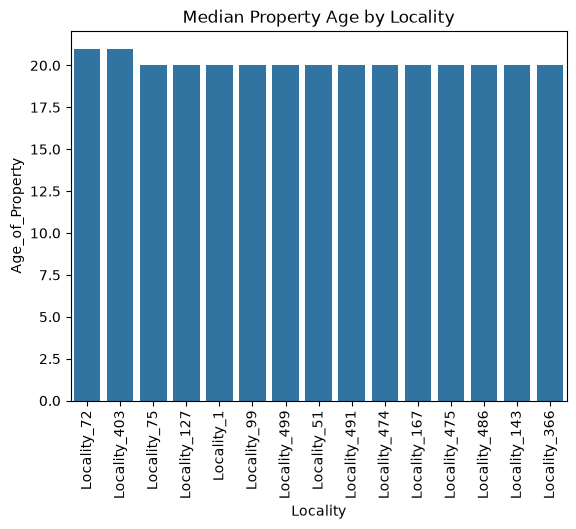

In [34]:
top_localities = (
    df.groupby("Locality")["Age_of_Property"]
    .median()
    .sort_values(ascending=False)
    .head(15)
    .reset_index()
)

sns.barplot(
    data=top_localities,
    x="Locality",
    y="Age_of_Property"
)

plt.title("Median Property Age by Locality")
plt.xticks(rotation=90)
plt.show()

How is BHK distributed across cities?

In [35]:
bhk_distribution = pd.crosstab(df["City"], df["BHK"])

bhk_distribution

BHK,1,2,3,4,5
City,,,,,
Ahmedabad,1264,1267,1272,1258,1350
Amritsar,1284,1239,1234,1224,1240
Bangalore,839,823,802,833,847
Bhopal,1238,1235,1255,1259,1297
Bhubaneswar,1236,1293,1299,1217,1278
Bilaspur,1210,1252,1275,1268,1258
Chennai,1263,1232,1183,1257,1233
Coimbatore,1236,1301,1317,1345,1262
Cuttack,1320,1292,1301,1236,1209


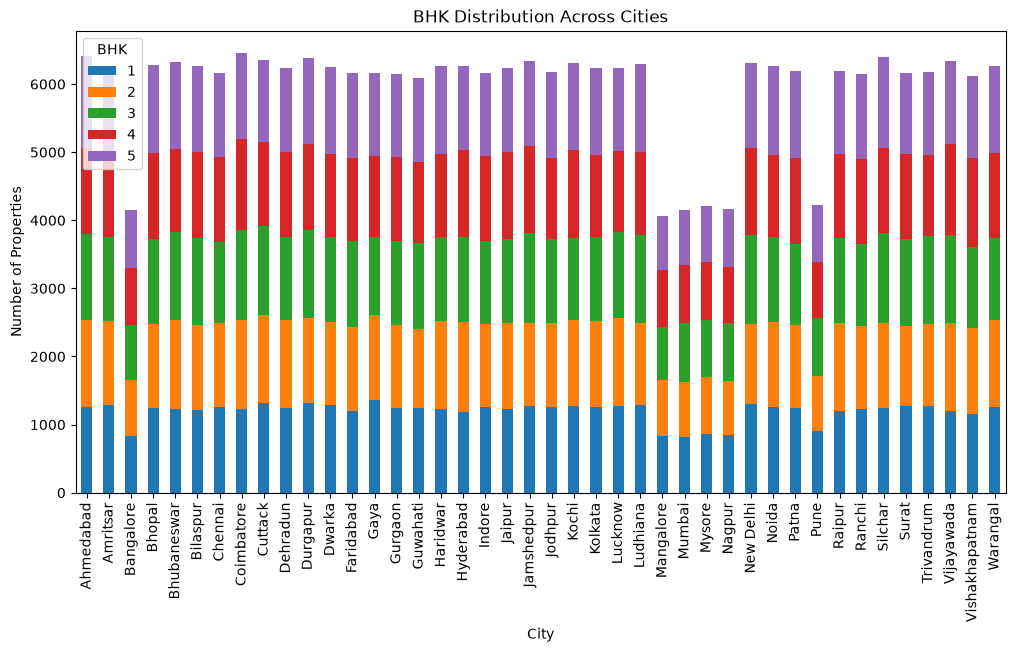

In [36]:
bhk_distribution.plot(
    kind="bar",
    stacked=True,
    figsize=(12,6)
)

plt.title("BHK Distribution Across Cities")
plt.xlabel("City")
plt.ylabel("Number of Properties")
plt.xticks(rotation=90)
plt.show()

What are the price trends for the top 5 most expensive localities?

In [37]:
top_5_localities = (
    df.groupby("Locality")["Price_in_Lakhs"]
    .mean()
    .nlargest(5)
)

top_5_localities

Locality
Locality_395    275.425987
Locality_366    273.411996
Locality_497    269.995540
Locality_360    269.806792
Locality_203    269.033716
Name: Price_in_Lakhs, dtype: float64

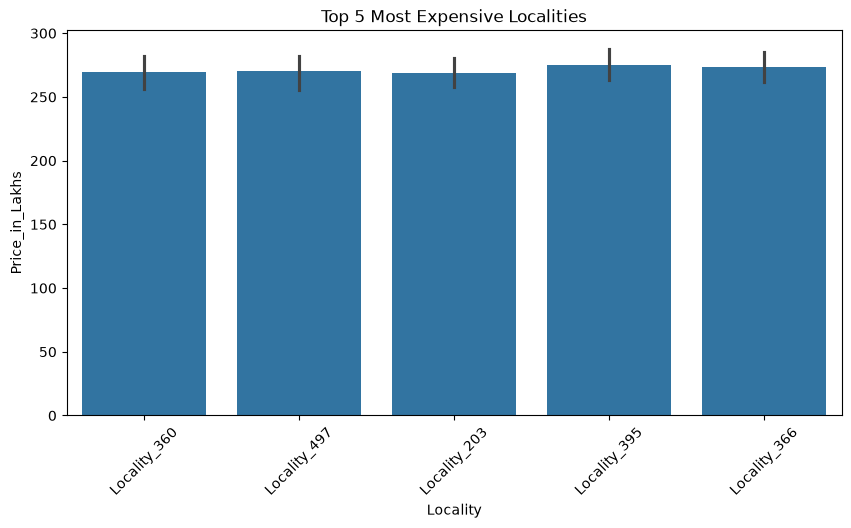

In [38]:
top_5_df = df[df["Locality"].isin(top_5_localities.index)]

plt.figure(figsize=(10,5))

sns.barplot(
    data=top_5_df,
    x="Locality",
    y="Price_in_Lakhs",
    estimator="mean"
)

plt.title("Top 5 Most Expensive Localities")
plt.xticks(rotation=45)
plt.show()

How are numeric features correlated with each other?

In [39]:
numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()

correlation

,ID,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Transport_Score,Infrastructure_Score
ID,1.000000,-0.001718,-0.002293,-0.001636,-0.001344,0.002734,-0.000214,0.003382,-0.002734,-0.001203,0.001429,0.003384,0.000822
BHK,-0.001718,1.000000,-0.001033,-0.000980,0.001174,0.000917,0.001263,-0.002862,-0.000917,-0.000762,0.001162,0.002017,0.000674
Size_in_SqFt,-0.002293,-0.001033,1.000000,-0.002529,-0.614533,0.004135,-0.002775,-0.003451,-0.004135,0.001966,-0.001695,0.001648,0.000516
Price_in_Lakhs,-0.001636,-0.000980,-0.002529,1.000000,0.555625,0.002714,-0.001719,0.001283,-0.002714,0.000155,-0.002769,0.000167,-0.001779
Price_per_SqFt,-0.001344,0.001174,-0.614533,0.555625,1.000000,-0.001212,-0.001906,0.004175,0.001212,-0.000094,-0.000145,-0.001838,-0.000528
Year_Built,0.002734,0.000917,0.004135,0.002714,-0.001212,1.000000,-0.000686,0.003452,-1.000000,-0.000591,-0.002719,0.003781,-0.001550
Floor_No,-0.000214,0.001263,-0.002775,-0.001719,-0.001906,-0.000686,1.000000,0.001169,0.000686,-0.000635,0.001428,-0.001150,0.000321
Total_Floors,0.003382,-0.002862,-0.003451,0.001283,0.004175,0.003452,0.001169,1.000000,-0.003452,-0.003093,-0.005867,0.001533,-0.005914
Age_of_Property,-0.002734,-0.000917,-0.004135,-0.002714,0.001212,-1.000000,0.000686,-0.003452,1.000000,0.000591,0.002719,-0.003781,0.001550
Nearby_Schools,-0.001203,-0.000762,0.001966,0.000155,-0.000094,-0.000591,-0.000635,-0.003093,0.000591,1.000000,-0.002246,-0.000583,0.693138


How are numeric features correlated with each other?

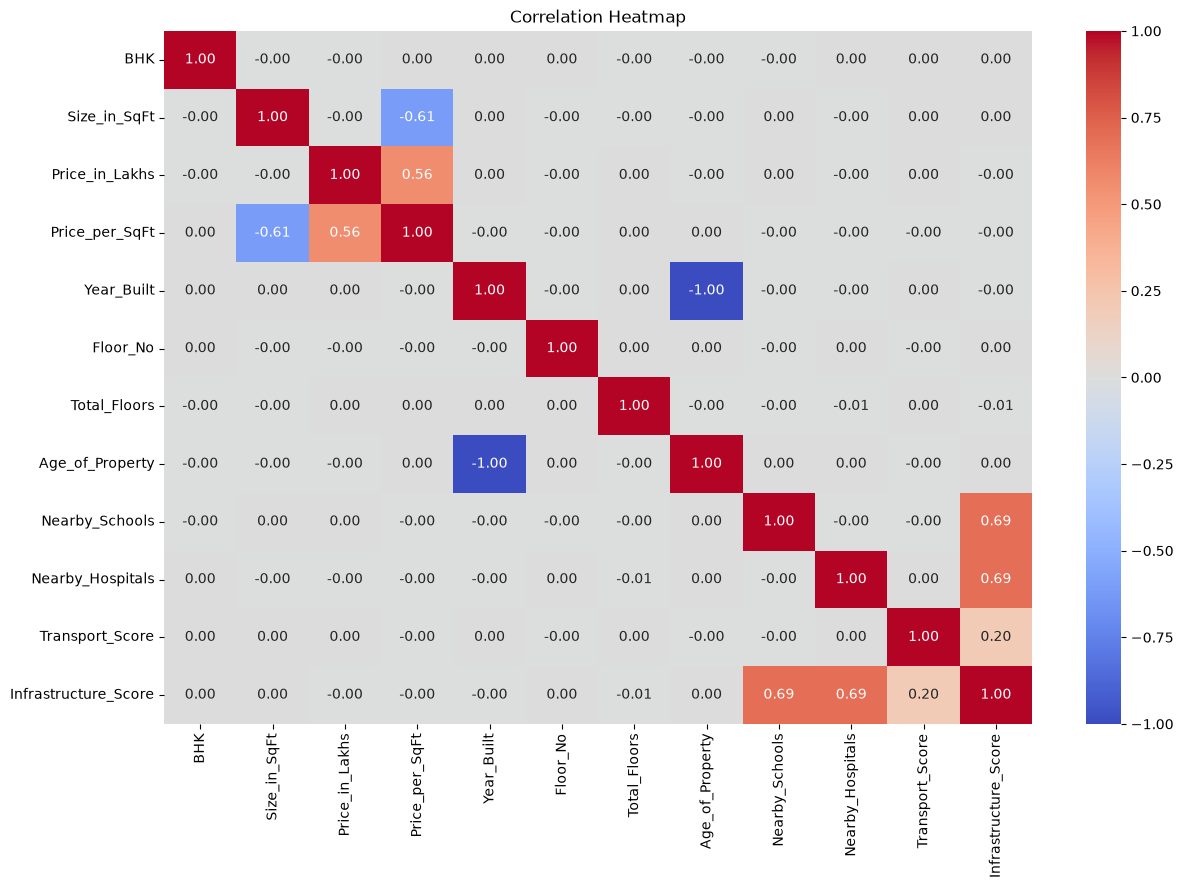

In [41]:
numeric_df = df.select_dtypes(include="number")

numeric_df = numeric_df.drop(
    columns=["ID"],
    errors="ignore"
)

plt.figure(figsize=(14, 9))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

How do nearby schools relate to price per sq ft?

In [42]:
df["Nearby_Schools"].corr(df["Price_per_SqFt"])

np.float64(-9.372746569009264e-05)

In [43]:
df.groupby("Nearby_Schools")["Price_per_SqFt"].mean()

Nearby_Schools
1     0.130644
2     0.131271
3     0.130708
4     0.128892
5     0.129943
6     0.132939
7     0.130440
8     0.129559
9     0.131041
10    0.130548
Name: Price_per_SqFt, dtype: float64

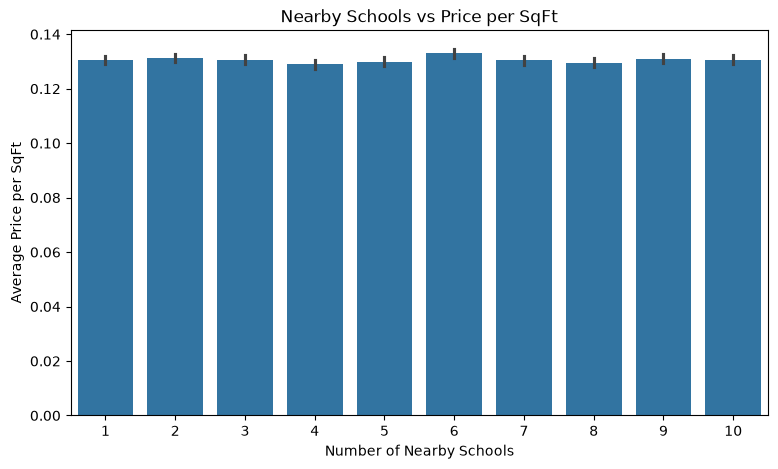

In [44]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=df,
    x="Nearby_Schools",
    y="Price_per_SqFt"
)

plt.title("Nearby Schools vs Price per SqFt")
plt.xlabel("Number of Nearby Schools")
plt.ylabel("Average Price per SqFt")
plt.show()

How do nearby hospitals relate to price per sq ft?

In [46]:
df["Nearby_Hospitals"].corr(df["Price_per_SqFt"])

np.float64(-0.00014481473232481258)

How does price vary by furnished status?

In [47]:
df.groupby("Furnished_Status")["Price_in_Lakhs"].mean()

Furnished_Status
Furnished         254.445550
Semi-furnished    254.334836
Unfurnished       254.979752
Name: Price_in_Lakhs, dtype: float64

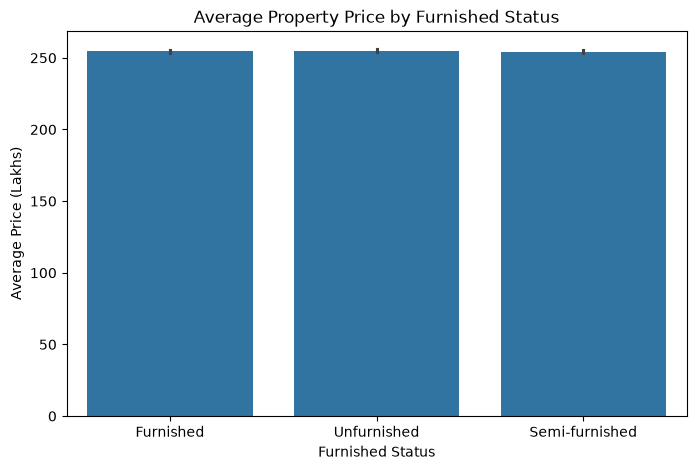

In [9]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=df,
    x="Furnished_Status",
    y="Price_in_Lakhs",
    estimator="mean"
)

plt.title("Average Property Price by Furnished Status")
plt.xlabel("Furnished Status")
plt.ylabel("Average Price (Lakhs)")
plt.show()

How does price per sq ft vary by property facing direction?

In [49]:
df.groupby("Facing")["Price_per_SqFt"].mean().sort_values(ascending=False)

Facing
West     0.131420
South    0.130457
East     0.130255
North    0.130252
Name: Price_per_SqFt, dtype: float64

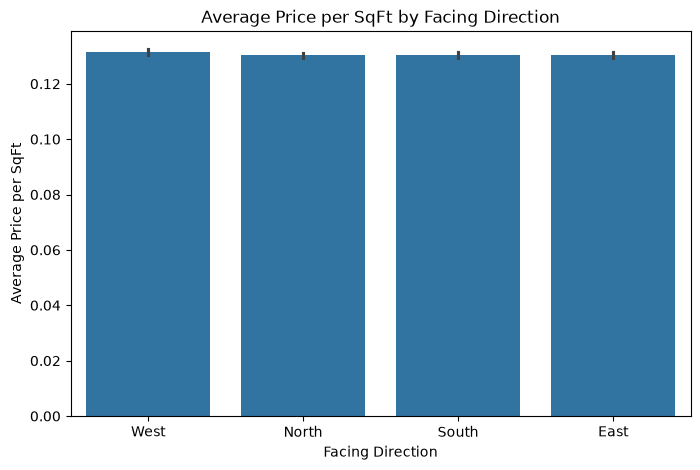

In [50]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=df,
    x="Facing",
    y="Price_per_SqFt",
    estimator="mean"
)

plt.title("Average Price per SqFt by Facing Direction")
plt.xlabel("Facing Direction")
plt.ylabel("Average Price per SqFt")
plt.show()

How many properties belong to each owner type?

In [2]:
df["Owner_Type"].value_counts()

Owner_Type
Broker     83479
Owner      83268
Builder    83253
Name: count, dtype: int64

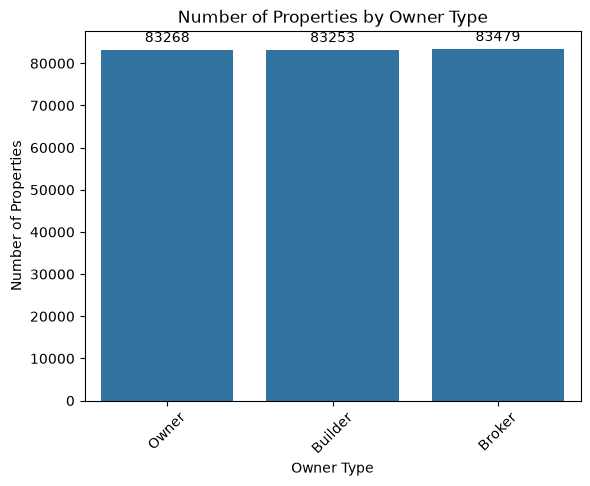

In [10]:
ax = sns.countplot(data=df, x="Owner_Type")

ax.bar_label(ax.containers[0], padding=3)

plt.title("Number of Properties by Owner Type")
plt.xlabel("Owner Type")
plt.ylabel("Number of Properties")
plt.xticks(rotation=45)
plt.show()

How many properties are available under each availability status?

In [11]:
df["Availability_Status"].value_counts()

Availability_Status
Under_Construction    125035
Ready_to_Move         124965
Name: count, dtype: int64

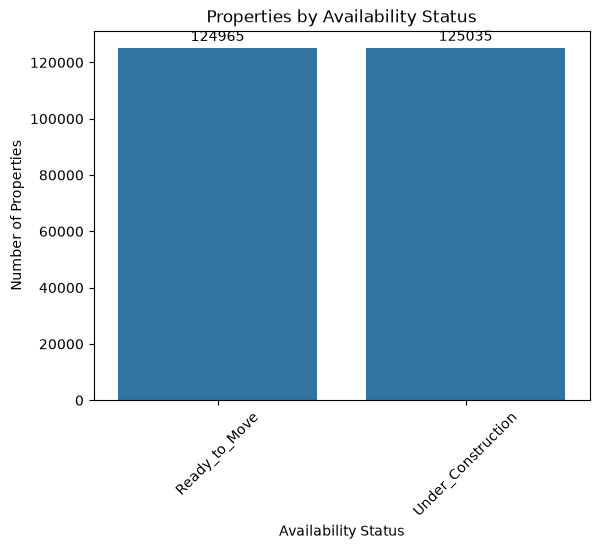

In [12]:
bx = sns.countplot(data=df, x="Availability_Status")
bx.bar_label(bx.containers[0], padding=3)
plt.title("Properties by Availability Status")
plt.xlabel("Availability Status")
plt.ylabel("Number of Properties")
plt.xticks(rotation=45)
plt.show()

Does parking space affect property price?

In [13]:
df.groupby("Parking_Space")["Price_in_Lakhs"].mean()

Parking_Space
No     254.429369
Yes    254.745492
Name: Price_in_Lakhs, dtype: float64

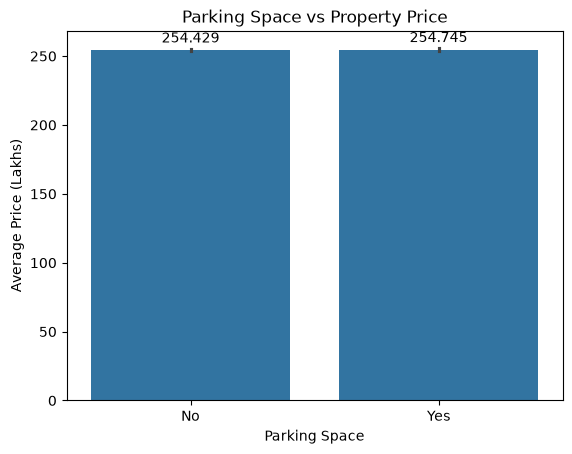

In [14]:
cx = sns.barplot(
    data=df,
    x="Parking_Space",
    y="Price_in_Lakhs",
    estimator="mean"
)
cx.bar_label(cx.containers[0], padding=3)

plt.title("Parking Space vs Property Price")
plt.xlabel("Parking Space")
plt.ylabel("Average Price (Lakhs)")
plt.show()

How do amenities affect price per sq ft?

In [15]:
df.groupby("Amenities")["Price_per_SqFt"].mean().sort_values(ascending=False)

Amenities
Clubhouse, Pool, Garden, Playground         0.150539
Pool, Gym, Clubhouse, Playground, Garden    0.146820
Garden, Clubhouse, Pool, Gym, Playground    0.146542
Playground, Gym, Clubhouse, Garden          0.144371
Clubhouse, Playground, Garden, Pool, Gym    0.143890
                                              ...   
Clubhouse, Gym, Garden, Pool                0.118761
Clubhouse, Pool, Playground, Garden, Gym    0.118053
Clubhouse, Garden, Playground, Gym          0.117418
Gym, Clubhouse, Pool, Playground            0.117230
Playground, Garden, Gym, Clubhouse, Pool    0.114091
Name: Price_per_SqFt, Length: 325, dtype: float64

In [17]:
df["Amenities"].nunique()

325

In [18]:
df["Amenities"].value_counts().head(10)

Amenities
Pool                 10218
Clubhouse            10010
Garden               10006
Gym                   9938
Playground            9934
Pool, Playground      2545
Gym, Pool             2534
Garden, Clubhouse     2524
Gym, Playground       2524
Playground, Gym       2519
Name: count, dtype: int64

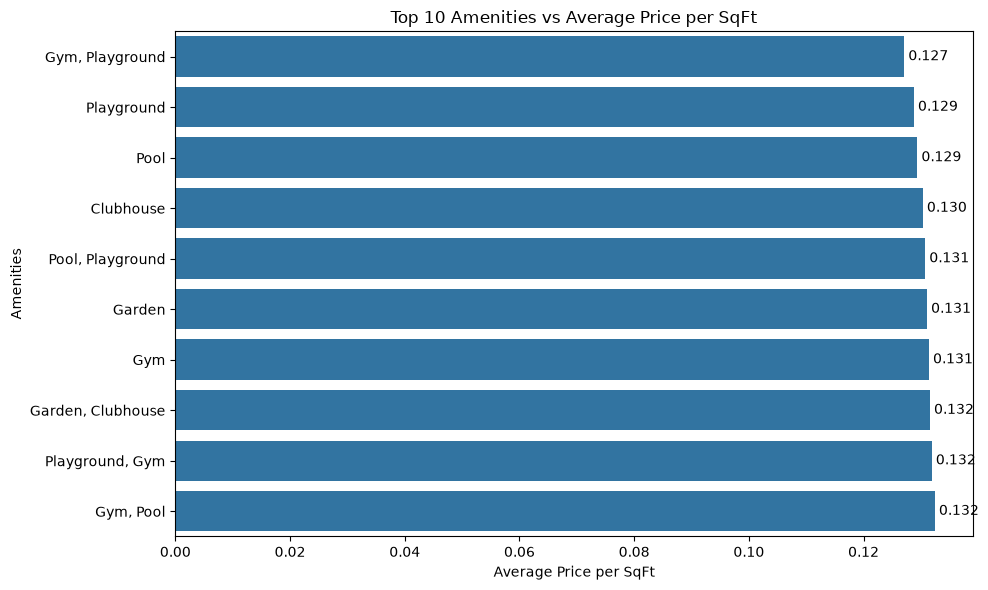

In [19]:
top_amenities = df["Amenities"].value_counts().head(10).index

amenity_price = (
    df[df["Amenities"].isin(top_amenities)]
    .groupby("Amenities")["Price_per_SqFt"]
    .mean()
    .sort_values(ascending=True)
    .reset_index()
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=amenity_price,
    x="Price_per_SqFt",
    y="Amenities"
)

ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)

plt.title("Top 10 Amenities vs Average Price per SqFt")
plt.xlabel("Average Price per SqFt")
plt.ylabel("Amenities")
plt.tight_layout()
plt.show()

How does public transport accessibility relate to price per sq ft or investment potential?

In [20]:
df.groupby("Public_Transport_Accessibility")["Price_per_SqFt"].mean()

Public_Transport_Accessibility
High      0.130286
Low       0.130874
Medium    0.130632
Name: Price_per_SqFt, dtype: float64

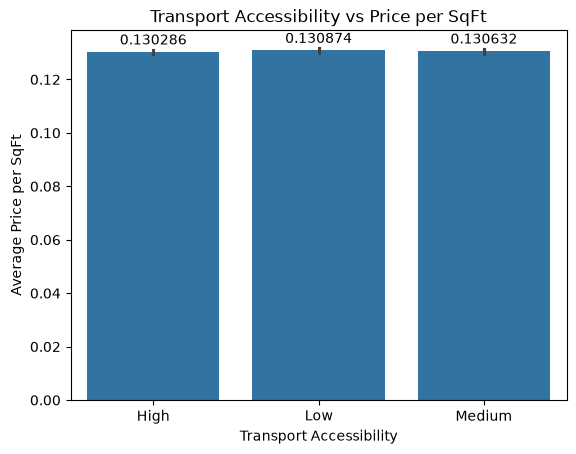

In [22]:
px = sns.barplot(
    data=df,
    x="Public_Transport_Accessibility",
    y="Price_per_SqFt",
    estimator="mean"
)
px.bar_label(px.containers[0], padding=3)

plt.title("Transport Accessibility vs Price per SqFt")
plt.xlabel("Transport Accessibility")
plt.ylabel("Average Price per SqFt")
plt.show()

In [3]:
df["City"].value_counts().head(10)

City
Coimbatore     6461
Ahmedabad      6411
Silchar        6404
Durgapur       6387
Cuttack        6358
Vijayawada     6344
Jamshedpur     6335
Bhubaneswar    6323
New Delhi      6306
Kochi          6305
Name: count, dtype: int64

In [3]:
df.columns

Index(['ID', 'State', 'City', 'Locality', 'Property_Type', 'BHK',
       'Size_in_SqFt', 'Price_in_Lakhs', 'Price_per_SqFt', 'Year_Built',
       'Furnished_Status', 'Floor_No', 'Total_Floors', 'Age_of_Property',
       'Nearby_Schools', 'Nearby_Hospitals', 'Public_Transport_Accessibility',
       'Parking_Space', 'Security', 'Amenities', 'Facing', 'Owner_Type',
       'Availability_Status'],
      dtype='str')

classification

In [4]:
median_price = df["Price_in_Lakhs"].median()

print("Median Property Price:", median_price)

Median Property Price: 253.87


In [5]:
median_price_sqft = df["Price_per_SqFt"].median()

print("Median Price per SqFt:", median_price_sqft)

Median Price per SqFt: 0.09


Create Good_Investment Column


In [7]:
df["Good_Investment"] = (
    (df["Price_in_Lakhs"] <= median_price) &
    (df["Price_per_SqFt"] <= median_price_sqft)
).astype(int)

In [8]:
df["Good_Investment"].value_counts()

Good_Investment
0    150322
1     99678
Name: count, dtype: int64

In [9]:
df[["Price_in_Lakhs", "Price_per_SqFt", "Good_Investment"]].head(10)

,Price_in_Lakhs,Price_per_SqFt,Good_Investment
0,489.76,0.10,0
1,195.52,0.08,1
2,183.79,0.05,1
3,300.29,0.11,0
4,182.90,0.04,1
5,135.28,0.04,1
6,318.12,0.07,0
7,141.39,0.03,1
8,189.16,0.07,1
9,187.42,0.13,0


In [10]:
features = [
    "BHK",
    "Size_in_SqFt",
    "Price_in_Lakhs",
    "Price_per_SqFt",
    "Year_Built",
    "Age_of_Property",
    "Nearby_Schools",
    "Nearby_Hospitals",
    "Floor_No",
    "Total_Floors"
]

X = df[features]
y = df["Good_Investment"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (250000, 10)
Target Shape: (250000,)


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (200000, 10)
Testing Data: (50000, 10)


In [12]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Model Training Completed!")

Model Training Completed!


In [13]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Predict test data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Model Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     30064
           1       1.00      1.00      1.00     19936

    accuracy                           1.00     50000
   macro avg       1.00      1.00      1.00     50000
weighted avg       1.00      1.00      1.00     50000


Confusion Matrix:
[[30064     0]
 [    0 19936]]


In [14]:
import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

            Feature  Importance
3    Price_per_SqFt    0.481452
2    Price_in_Lakhs    0.448698
1      Size_in_SqFt    0.068924
8          Floor_No    0.000181
9      Total_Floors    0.000174
7  Nearby_Hospitals    0.000131
5   Age_of_Property    0.000129
4        Year_Built    0.000124
6    Nearby_Schools    0.000106
0               BHK    0.000080


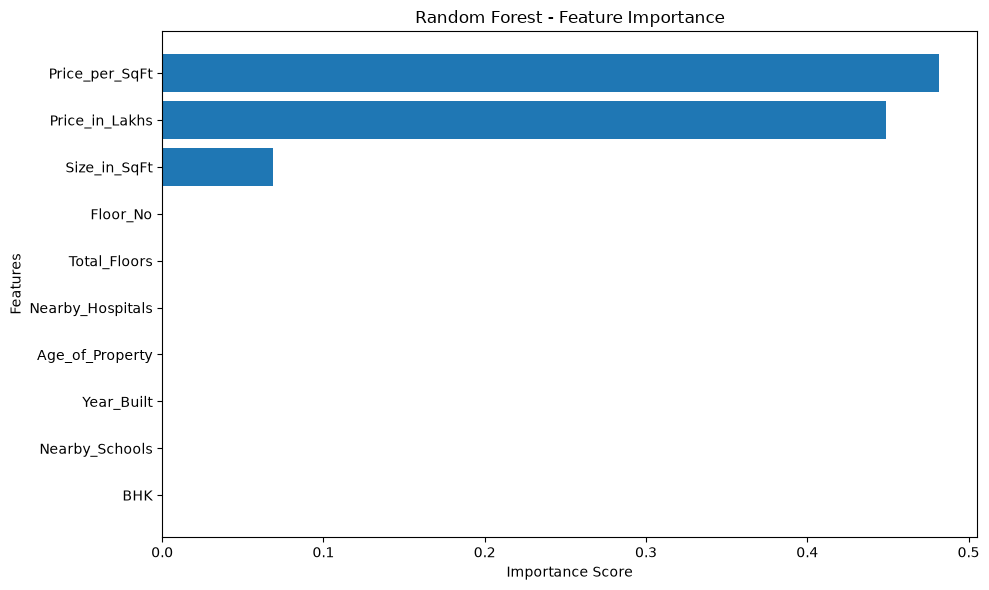

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Random Forest - Feature Importance")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [16]:
y_pred_proba = model.predict_proba(X_test)

print(y_pred_proba[:5])

[[1. 0.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [1. 0.]]


In [17]:
confidence = y_pred_proba.max(axis=1)

print(confidence[:10])

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


Future Price Calculation

In [19]:
growth_rate = 0.08
years = 5

future_price = df["Price_in_Lakhs"] * (1 + growth_rate) ** years

df["Estimated_Price_After_5_Years"] = future_price

df[["Price_in_Lakhs", "Estimated_Price_After_5_Years"]].head(10)

,Price_in_Lakhs,Estimated_Price_After_5_Years
0,489.76,719.618119
1,195.52,287.283026
2,183.79,270.047807
3,300.29,441.224528
4,182.90,268.740105
5,135.28,198.770702
6,318.12,467.422648
7,141.39,207.748297
8,189.16,277.938099
9,187.42,275.381468


In [20]:
df["Expected_Price_Increase"] = (
    df["Estimated_Price_After_5_Years"] - df["Price_in_Lakhs"]
)

df[[
    "Price_in_Lakhs",
    "Estimated_Price_After_5_Years",
    "Expected_Price_Increase"
]].head(10)


,Price_in_Lakhs,Estimated_Price_After_5_Years,Expected_Price_Increase
0,489.76,719.618119,229.858119
1,195.52,287.283026,91.763026
2,183.79,270.047807,86.257807
3,300.29,441.224528,140.934528
4,182.90,268.740105,85.840105
5,135.28,198.770702,63.490702
6,318.12,467.422648,149.302648
7,141.39,207.748297,66.358297
8,189.16,277.938099,88.778099
9,187.42,275.381468,87.961468


Calculate Average Future Price

In [21]:
print("Average Current Price:",
      df["Price_in_Lakhs"].mean())

print("Average Future Price:",
      df["Estimated_Price_After_5_Years"].mean())

print("Average Expected Increase:",
      df["Expected_Price_Increase"].mean())

Average Current Price: 254.58685404
Average Future Price: 374.0716126251557
Average Expected Increase: 119.48475858515565


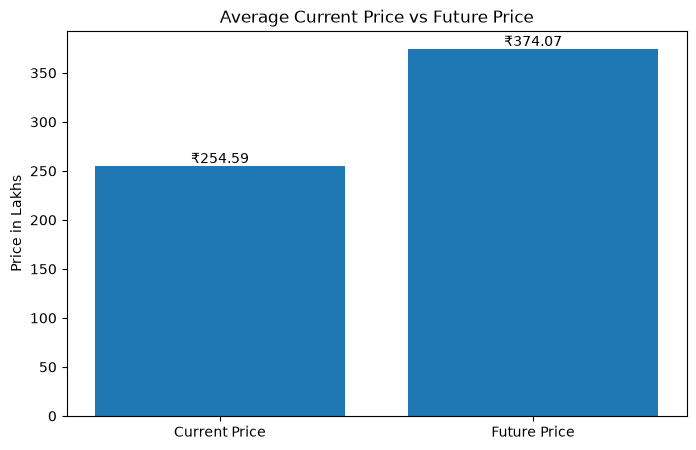

In [23]:
plt.figure(figsize=(8, 5))
bars = plt.bar(labels, values)

plt.title("Average Current Price vs Future Price")
plt.ylabel("Price in Lakhs")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"₹{bar.get_height():.2f}",
        ha="center",
        va="bottom"
    )

plt.show()

City-wise Future Price Estimation

In [24]:
city_analysis = df.groupby("City").agg(
    Average_Current_Price=("Price_in_Lakhs", "mean"),
    Average_Future_Price=("Estimated_Price_After_5_Years", "mean")
).reset_index()

city_analysis.head(10)

,City,Average_Current_Price,Average_Future_Price
0,Ahmedabad,253.586827,372.602245
1,Amritsar,252.429802,370.902196
2,Bangalore,258.456639,379.757596
3,Bhopal,256.498896,376.881029
4,Bhubaneswar,254.902173,374.534920
5,Bilaspur,251.879267,370.093279
6,Chennai,256.830172,377.367782
7,Coimbatore,256.504745,376.889624
8,Cuttack,250.786672,368.487898
9,Dehradun,256.890115,377.455859


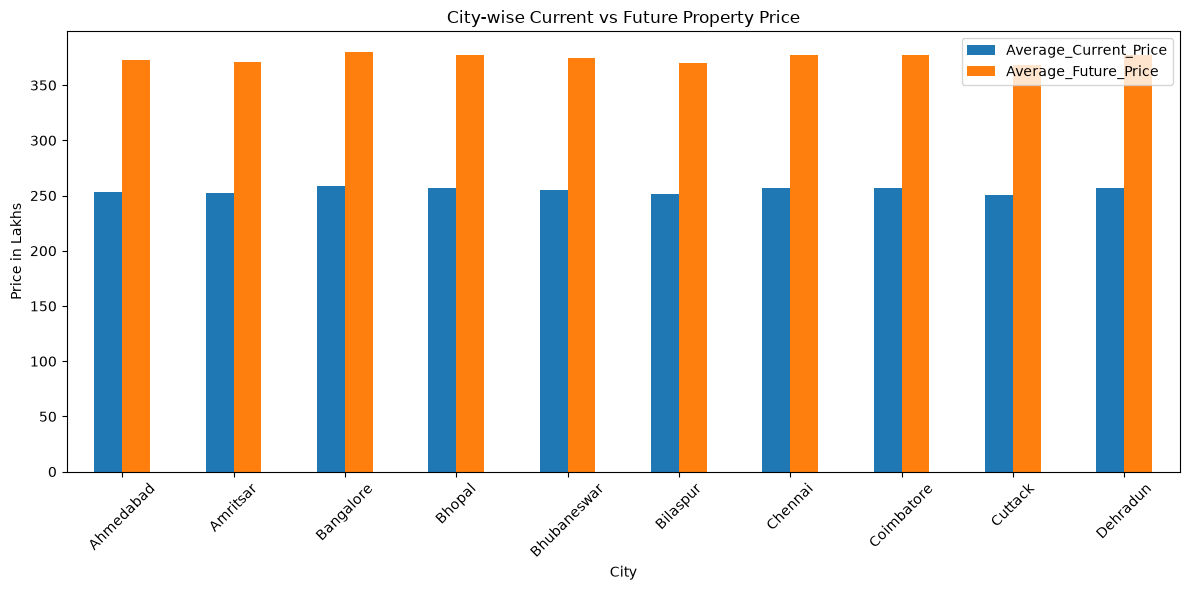

In [25]:
city_top10 = city_analysis.head(10)

city_top10.plot(
    x="City",
    y=["Average_Current_Price", "Average_Future_Price"],
    kind="bar",
    figsize=(12, 6)
)

plt.title("City-wise Current vs Future Property Price")
plt.xlabel("City")
plt.ylabel("Price in Lakhs")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

 Property Type-wise Future Price Analysis

In [26]:
property_analysis = df.groupby("Property_Type").agg(
    Average_Current_Price=("Price_in_Lakhs", "mean"),
    Average_Future_Price=("Estimated_Price_After_5_Years", "mean")
).reset_index()

property_analysis

,Property_Type,Average_Current_Price,Average_Future_Price
0,Apartment,254.622116,374.123424
1,Independent House,255.374150,375.228408
2,Villa,253.768802,372.869626


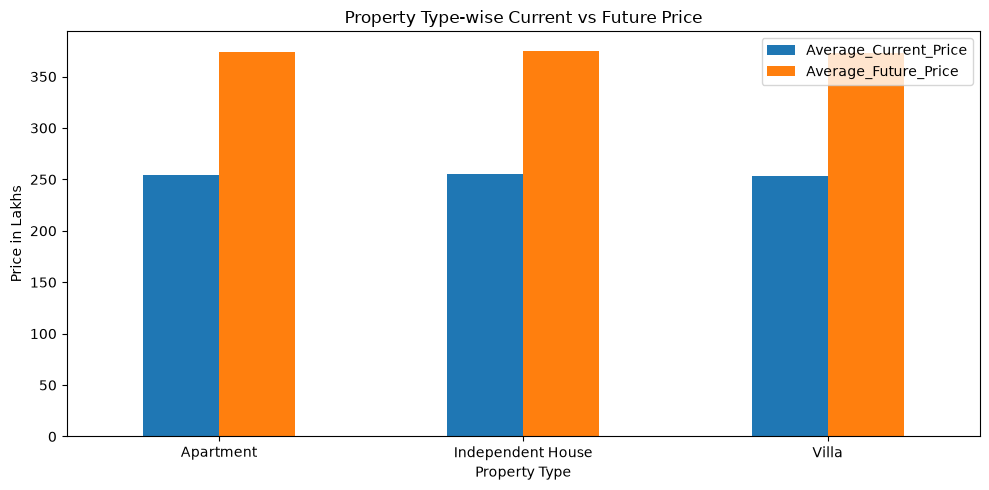

In [27]:
property_analysis.plot(
    x="Property_Type",
    y=["Average_Current_Price", "Average_Future_Price"],
    kind="bar",
    figsize=(10, 5)
)

plt.title("Property Type-wise Current vs Future Price")
plt.xlabel("Property Type")
plt.ylabel("Price in Lakhs")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

In [28]:
print("Total Properties:", len(df))

print("Average Current Price:",
      round(df["Price_in_Lakhs"].mean(), 2))

print("Average Future Price:",
      round(df["Estimated_Price_After_5_Years"].mean(), 2))

print("Average Expected Increase:",
      round(df["Expected_Price_Increase"].mean(), 2))

print("Annual Growth Rate: 8%")
print("Prediction Period: 5 Years")

Total Properties: 250000
Average Current Price: 254.59
Average Future Price: 374.07
Average Expected Increase: 119.48
Annual Growth Rate: 8%
Prediction Period: 5 Years


In [29]:
df.to_csv("real_estate_processed.csv", index=False)

In [30]:
import joblib

joblib.dump(model, "investment_model.pkl")

['investment_model.pkl']